# MaNGA Stellar Kinematics — FITS Metadata Exploration

**Observation:** MaNGA plate-IFU `8138-12704`  
**Data release:** SDSS DR17  
**DAP method:** `HYB10-MILESHC-MASTARSSP`

## Purpose

This notebook explores the three downloaded MaNGA products before extracting stellar kinematics:

1. DRP `LOGCUBE`: observed spectra and instrumental/data-quality information.
2. DAP `LOGCUBE`: spectral-model products.
3. DAP `MAPS`: spatially resolved measurements, including stellar velocity and velocity dispersion.

**Important:** This notebook is for inspection and exploratory visualization. It does not yet create the final scientifically quality-controlled kinematic maps.


## 1. Imports and project paths

The path-discovery code searches the current working directory and its parent folders for `data/raw`. This works whether VS Code starts the notebook from the project root or from the `notebooks` directory.

If automatic discovery fails, set `PROJECT_ROOT` manually.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from astropy.io import fits

# Find the project root robustly.
current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in [current, *current.parents]
     if (p / "data" / "raw").is_dir()),
    None
)

# Optional manual override:
# PROJECT_ROOT = Path(r"D:\KS\manga-stellar-kinematics")

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate data/raw from the notebook working directory. "
        "Set PROJECT_ROOT manually."
    )

DATA_DIR = PROJECT_ROOT / "data" / "raw"

MAPS_PATH = DATA_DIR / (
    "manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits.gz"
)
DRP_CUBE_PATH = DATA_DIR / "manga-8138-12704-LOGCUBE.fits.gz"
DAP_CUBE_PATH = DATA_DIR / (
    "manga-8138-12704-LOGCUBE-HYB10-MILESHC-MASTARSSP.fits.gz"
)

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)

required_files = {
    "MAPS": MAPS_PATH,
    "DRP LOGCUBE": DRP_CUBE_PATH,
    "DAP LOGCUBE": DAP_CUBE_PATH,
}

for label, path in required_files.items():
    if path.is_file():
        print(f"{label:12s}: FOUND | {path.stat().st_size / 1024**2:.2f} MB")
    else:
        print(f"{label:12s}: MISSING | {path}")

missing = [str(p) for p in required_files.values() if not p.is_file()]
if missing:
    raise FileNotFoundError("Missing FITS file(s):\n" + "\n".join(missing))


Project root: D:\KS\manga-stellar-kinematics
Data directory: D:\KS\manga-stellar-kinematics\data\raw
MAPS        : FOUND | 10.49 MB
DRP LOGCUBE : FOUND | 192.21 MB
DAP LOGCUBE : FOUND | 214.33 MB


## 2. Open the FITS products

We use read-only mode. `memmap=False` avoids memory-mapped file handles, at the cost of loading data into memory when accessed. The LOGCUBE files are moderately large, so avoid making unnecessary full-cube copies.

If you rerun this cell, previously opened HDULists are closed first.


In [2]:
# Close handles left open by an earlier execution of this cell.
for variable_name in ("maps", "drp_cube", "dap_cube"):
    old_hdul = globals().get(variable_name)
    if old_hdul is not None:
        try:
            old_hdul.close()
        except Exception:
            pass

maps = fits.open(MAPS_PATH, mode="readonly", memmap=False)
drp_cube = fits.open(DRP_CUBE_PATH, mode="readonly", memmap=False)
dap_cube = fits.open(DAP_CUBE_PATH, mode="readonly", memmap=False)

print("MAPS HDUs:", len(maps))
print("DRP LOGCUBE HDUs:", len(drp_cube))
print("DAP LOGCUBE HDUs:", len(dap_cube))

print("\nMAPS inventory:")
maps.info()


MAPS HDUs: 64
DRP LOGCUBE HDUs: 24
DAP LOGCUBE HDUs: 13

MAPS inventory:
Filename: D:\KS\manga-stellar-kinematics\data\raw\manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits.gz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     147   ()      
  1  SPX_SKYCOO    1 ImageHDU        44   (72, 72, 2)   float32   
  2  SPX_ELLCOO    1 ImageHDU        49   (72, 72, 4)   float32   
  3  SPX_MFLUX     1 ImageHDU        37   (72, 72)   float32   
  4  SPX_MFLUX_IVAR    1 ImageHDU        38   (72, 72)   float32   
  5  SPX_SNR       1 ImageHDU        35   (72, 72)   float32   
  6  BINID         1 ImageHDU        46   (72, 72, 5)   int32   
  7  BIN_LWSKYCOO    1 ImageHDU        44   (72, 72, 2)   float32   
  8  BIN_LWELLCOO    1 ImageHDU        49   (72, 72, 4)   float32   
  9  BIN_AREA      1 ImageHDU        36   (72, 72)   float32   
 10  BIN_FAREA     1 ImageHDU        35   (72, 72)   float32   
 11  BIN_MFLUX     1 ImageHDU        38   (72, 72

## 3. Inspect primary-header metadata

The primary HDU often contains observation-level and pipeline metadata even when it has no image array. Not every keyword is guaranteed to occur in every product; missing values are reported rather than guessed.


In [3]:
def inspect_primary_header(hdul, product_name):
    header = hdul[0].header
    keys = [
        "TELESCOP", "INSTRUME", "PLATEID", "PLATEIFU",
        "MANGAID", "IFUDSGN", "DAPTYPE",
        "VERSDRP2", "VERSDRP3", "VERSDAP",
        "DAPQUAL", "OBJRA", "OBJDEC", "IFURA", "IFUDEC",
        "NAXIS", "EXTEND",
    ]

    print(f"\n{product_name} — PRIMARY HEADER")
    print("-" * 76)
    for key in keys:
        print(f"{key:12s}: {header.get(key, 'Not available')}")

inspect_primary_header(maps, "MAPS")
inspect_primary_header(drp_cube, "DRP LOGCUBE")
inspect_primary_header(dap_cube, "DAP LOGCUBE")



MAPS — PRIMARY HEADER
----------------------------------------------------------------------------
TELESCOP    : SDSS 2.5-M
INSTRUME    : MaNGA
PLATEID     : 8138
PLATEIFU    : 8138-12704
MANGAID     : 1-339041
IFUDSGN     : 12704
DAPTYPE     : HYB10-MILESHC-MASTARSSP
VERSDRP2    : v3_1_1
VERSDRP3    : v3_1_1
VERSDAP     : 3.1.0
DAPQUAL     : 0
OBJRA       : 116.657135061
OBJDEC      : 44.7905163357
IFURA       : 116.65714
IFUDEC      : 44.790516
NAXIS       : 0
EXTEND      : True

DRP LOGCUBE — PRIMARY HEADER
----------------------------------------------------------------------------
TELESCOP    : SDSS 2.5-M
INSTRUME    : MaNGA
PLATEID     : 8138
PLATEIFU    : 8138-12704
MANGAID     : 1-339041
IFUDSGN     : 12704
DAPTYPE     : Not available
VERSDRP2    : v3_1_1
VERSDRP3    : v3_1_1
VERSDAP     : Not available
DAPQUAL     : Not available
OBJRA       : 116.657135061
OBJDEC      : 44.7905163357
IFURA       : 116.65714
IFUDEC      : 44.790516
NAXIS       : 0
EXTEND      : True

DAP LOGC

## 4. Compare the three products

This compact comparison helps confirm that the files refer to the same observation and identify the DAP analysis configuration.


In [4]:
def compare_metadata(hdul, product_name):
    header = hdul[0].header
    keys = [
        "PLATEID", "PLATEIFU", "MANGAID", "IFUDSGN",
        "DAPTYPE", "VERSDRP2", "VERSDRP3", "VERSDAP",
        "OBJRA", "OBJDEC", "IFURA", "IFUDEC", "DAPQUAL",
    ]

    print(f"\n{product_name}")
    print("-" * 64)
    for key in keys:
        print(f"{key:12s}: {header.get(key, 'Not available')}")

compare_metadata(maps, "MAPS")
compare_metadata(drp_cube, "DRP LOGCUBE")
compare_metadata(dap_cube, "DAP LOGCUBE")



MAPS
----------------------------------------------------------------
PLATEID     : 8138
PLATEIFU    : 8138-12704
MANGAID     : 1-339041
IFUDSGN     : 12704
DAPTYPE     : HYB10-MILESHC-MASTARSSP
VERSDRP2    : v3_1_1
VERSDRP3    : v3_1_1
VERSDAP     : 3.1.0
OBJRA       : 116.657135061
OBJDEC      : 44.7905163357
IFURA       : 116.65714
IFUDEC      : 44.790516
DAPQUAL     : 0

DRP LOGCUBE
----------------------------------------------------------------
PLATEID     : 8138
PLATEIFU    : 8138-12704
MANGAID     : 1-339041
IFUDSGN     : 12704
DAPTYPE     : Not available
VERSDRP2    : v3_1_1
VERSDRP3    : v3_1_1
VERSDAP     : Not available
OBJRA       : 116.657135061
OBJDEC      : 44.7905163357
IFURA       : 116.65714
IFUDEC      : 44.790516
DAPQUAL     : Not available

DAP LOGCUBE
----------------------------------------------------------------
PLATEID     : 8138
PLATEIFU    : 8138-12704
MANGAID     : 1-339041
IFUDSGN     : 12704
DAPTYPE     : HYB10-MILESHC-MASTARSSP
VERSDRP2    : v3_1_1
VER

## 5. Inspect the stellar-kinematics MAPS extensions

These are the principal measurements for this project.

- `STELLAR_VEL`: stellar line-of-sight velocity.
- `STELLAR_SIGMA`: stellar line-of-sight velocity dispersion.
- `*_IVAR`: inverse variance, not standard deviation.
- `*_MASK`: bit-encoded quality flags.
- `STELLAR_SIGMACORR`: dispersion correction information.

Always inspect the header units and mask metadata before interpreting numerical values.


In [5]:
stellar_extensions = [
    "STELLAR_VEL",
    "STELLAR_SIGMA",
    "STELLAR_SIGMACORR",
    "STELLAR_VEL_IVAR",
    "STELLAR_SIGMA_IVAR",
    "STELLAR_VEL_MASK",
    "STELLAR_SIGMA_MASK",
]

maps_names = {hdu.name.upper() for hdu in maps}

for name in stellar_extensions:
    if name not in maps_names:
        print(f"\n{name}: NOT FOUND")
        continue

    hdu = maps[name]
    print(f"\n{name}")
    print("Shape:       ", None if hdu.data is None else hdu.data.shape)
    print("BUNIT:       ", hdu.header.get("BUNIT", "Not specified"))
    print("MASKNAME:    ", hdu.header.get("MASKNAME", "Not specified"))
    print("HDUCLAS2:    ", hdu.header.get("HDUCLAS2", "Not specified"))
    print("ERRDATA:     ", hdu.header.get("ERRDATA", "Not specified"))



STELLAR_VEL
Shape:        (72, 72)
BUNIT:        km/s
MASKNAME:     MANGA_DAPPIXMASK
HDUCLAS2:     DATA
ERRDATA:      STELLAR_VEL_IVAR

STELLAR_SIGMA
Shape:        (72, 72)
BUNIT:        km/s
MASKNAME:     MANGA_DAPPIXMASK
HDUCLAS2:     DATA
ERRDATA:      STELLAR_SIGMA_IVAR

STELLAR_SIGMACORR
Shape:        (2, 72, 72)
BUNIT:        km/s
MASKNAME:     MANGA_DAPPIXMASK
HDUCLAS2:     DATA
ERRDATA:      Not specified

STELLAR_VEL_IVAR
Shape:        (72, 72)
BUNIT:        (km/s)^{-2}
MASKNAME:     MANGA_DAPPIXMASK
HDUCLAS2:     ERROR
ERRDATA:      Not specified

STELLAR_SIGMA_IVAR
Shape:        (72, 72)
BUNIT:        (km/s)^{-2}
MASKNAME:     MANGA_DAPPIXMASK
HDUCLAS2:     ERROR
ERRDATA:      Not specified

STELLAR_VEL_MASK
Shape:        (72, 72)
BUNIT:        Not specified
MASKNAME:     MANGA_DAPPIXMASK
HDUCLAS2:     QUALITY
ERRDATA:      STELLAR_VEL_IVAR

STELLAR_SIGMA_MASK
Shape:        (72, 72)
BUNIT:        Not specified
MASKNAME:     MANGA_DAPPIXMASK
HDUCLAS2:     QUALITY
ERRDATA:   

## 6. Inspect the DRP and DAP LOGCUBE extensions

The DRP LOGCUBE contains the observed spectral data. The DAP LOGCUBE contains model-related products. The two should not be confused.

The inventory below prints the extension name, array shape and declared unit.


In [6]:
def inspect_extensions(hdul, product_name):
    print(f"\n{product_name}")
    print("=" * 86)
    for index, hdu in enumerate(hdul):
        shape = hdu.data.shape if hdu.data is not None else "No data"
        unit = hdu.header.get("BUNIT", "Not specified")
        print(f"{index:02d} | {hdu.name:20s} | shape={str(shape):20s} | unit={unit}")

inspect_extensions(drp_cube, "DRP LOGCUBE")
inspect_extensions(dap_cube, "DAP LOGCUBE")



DRP LOGCUBE
00 | PRIMARY              | shape=No data              | unit=1E-17 erg/s/cm^2/Angstrom/spaxel
01 | FLUX                 | shape=(4563, 72, 72)       | unit=1E-17 erg/s/cm^2/Angstrom/spaxel
02 | IVAR                 | shape=(4563, 72, 72)       | unit=Not specified
03 | MASK                 | shape=(4563, 72, 72)       | unit=Not specified
04 | LSFPOST              | shape=(4563, 72, 72)       | unit=Not specified
05 | LSFPRE               | shape=(4563, 72, 72)       | unit=Not specified
06 | WAVE                 | shape=(4563,)              | unit=Not specified
07 | SPECRES              | shape=(4563,)              | unit=Not specified
08 | SPECRESD             | shape=(4563,)              | unit=Not specified
09 | PRESPECRES           | shape=(4563,)              | unit=Not specified
10 | PRESPECRESD          | shape=(4563,)              | unit=Not specified
11 | OBSINFO              | shape=(15,)                | unit=Not specified
12 | GIMG                 | shape=(72

## 7. Inspect wavelength calibration

The DRP LOGCUBE provides a `WAVE` extension containing the wavelength corresponding to each spectral channel. Use this array directly instead of reconstructing wavelengths from assumptions.

The plot below checks the wavelength coverage and sampling.


Number of wavelength samples: 4563
First wavelength: 3621.5959848601933
Last wavelength: 10353.805444147549
Wavelength unit: Check FITS documentation/header
All finite: True
Strictly increasing: True
First 10 samples: [3621.59598486 3622.42998417 3623.26417553 3624.098559   3624.93313461
 3625.76790241 3626.60286245 3627.43801476 3628.2733594  3629.10889641]


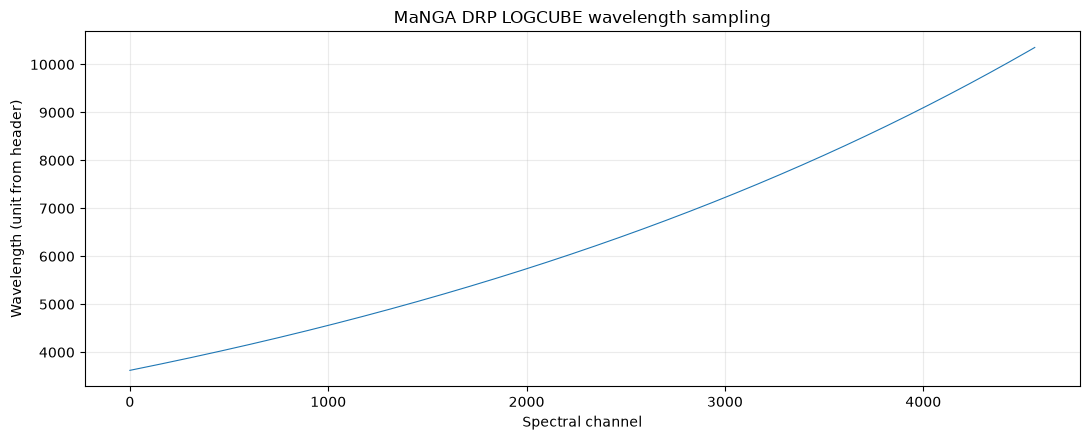

In [7]:
if "WAVE" not in {hdu.name.upper() for hdu in drp_cube}:
    raise KeyError("WAVE extension is missing from the DRP LOGCUBE.")

wave = np.asarray(drp_cube["WAVE"].data, dtype=float)
wave_header = drp_cube["WAVE"].header

print("Number of wavelength samples:", wave.size)
print("First wavelength:", wave[0])
print("Last wavelength:", wave[-1])
print("Wavelength unit:", wave_header.get("BUNIT", "Check FITS documentation/header"))
print("All finite:", np.all(np.isfinite(wave)))
print("Strictly increasing:", np.all(np.diff(wave) > 0))
print("First 10 samples:", wave[:10])

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(np.arange(wave.size), wave, linewidth=0.8)
ax.set_xlabel("Spectral channel")
ax.set_ylabel(f"Wavelength ({wave_header.get('BUNIT', 'unit from header')})")
ax.set_title("MaNGA DRP LOGCUBE wavelength sampling")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 8. Inspect spatial coordinate products

The MAPS product includes:

- `SPX_SKYCOO`: sky-coordinate information for individual spaxels.
- `SPX_ELLCOO`: elliptical coordinates relative to the adopted galaxy geometry.

These extensions have a leading coordinate axis. Inspect their headers before assigning a meaning or unit to each plane.


In [8]:
for name in ("SPX_SKYCOO", "SPX_ELLCOO"):
    if name not in maps_names:
        print(f"{name}: not present")
        continue

    hdu = maps[name]
    print(f"\n{name} header")
    print("-" * 70)
    print(hdu.header)

    data = np.asarray(hdu.data)
    print("Array shape:", data.shape)

    for plane_index in range(data.shape[0]):
        plane = data[plane_index]
        finite = np.isfinite(plane)
        print(
            f"Plane {plane_index}: "
            f"finite={finite.sum()}, "
            f"min={np.nanmin(plane):.6g}, "
            f"max={np.nanmax(plane):.6g}"
        )



SPX_SKYCOO header
----------------------------------------------------------------------
XTENSION= 'IMAGE   '           / Image extension                                BITPIX  =                  -32 / array data type                                NAXIS   =                    3 / number of array dimensions                     NAXIS1  =                   72                                                  NAXIS2  =                   72                                                  NAXIS3  =                    2                                                  PCOUNT  =                    0 / number of parameters                           GCOUNT  =                    1 / number of groups                               WCSAXES =                    3 / Number of coordinate axes                      CRPIX1  =                 37.0 / Pixel coordinate of reference point            CRPIX2  =                 37.0 / Pixel coordinate of reference point            CRPIX3  =                  1.0

## 9. Inspect stellar-kinematics masks

DAP masks are bitmasks: each bit represents a named condition. The numerical mask value is therefore not a simple quality score.

This cell reports the values present and checks the DAP `DONOTUSE` bit (bit 30). This is a diagnostic only; the final scientific mask must be based on the relevant mask definition and the project's analysis choices.


In [9]:
DONOTUSE_BIT = 30
DONOTUSE_VALUE = np.uint64(1) << np.uint64(DONOTUSE_BIT)

def inspect_mask(hdul, extension_name):
    mask = np.asarray(hdul[extension_name].data)

    # Convert safely to unsigned integers for bit operations.
    mask_u = mask.astype(np.uint64, copy=False)

    unique_values, counts = np.unique(mask_u, return_counts=True)

    print(f"\n{extension_name}")
    print("dtype:", mask.dtype)
    print("Unique mask values and counts:")
    for value, count in zip(unique_values, counts):
        print(f"  {int(value):12d}: {int(count)}")

    do_not_use = (mask_u & DONOTUSE_VALUE) != 0
    print(f"Pixels with DONOTUSE (bit {DONOTUSE_BIT}): {np.count_nonzero(do_not_use)}")
    print("Total pixels:", mask.size)

    return mask_u, do_not_use

velocity_mask, velocity_donotuse = inspect_mask(
    maps, "STELLAR_VEL_MASK"
)
sigma_mask, sigma_donotuse = inspect_mask(
    maps, "STELLAR_SIGMA_MASK"
)



STELLAR_VEL_MASK
dtype: >i4
Unique mask values and counts:
             0: 2704
    1073741840: 2480
Pixels with DONOTUSE (bit 30): 2480
Total pixels: 5184

STELLAR_SIGMA_MASK
dtype: >i4
Unique mask values and counts:
             0: 2704
    1073741840: 2480
Pixels with DONOTUSE (bit 30): 2480
Total pixels: 5184


## 10. Extract and plot a central-region observed spectrum

This is a simple exploratory spectrum made from a 3 × 3 spatial region near the cube centre.

We use finite flux values with positive inverse variance. This is a basic validity filter, not a complete interpretation of all DRP mask bits. The median is calculated wavelength-channel by wavelength-channel.

The plotted spectrum is the observed DRP flux, not the DAP stellar-continuum model.


In [10]:
flux = np.asarray(drp_cube["FLUX"].data, dtype=float)
ivar = np.asarray(drp_cube["IVAR"].data, dtype=float)

if flux.ndim != 3:
    raise ValueError(f"Expected a 3D FLUX cube, got shape {flux.shape}")

if flux.shape != ivar.shape:
    raise ValueError("FLUX and IVAR arrays have different shapes.")

n_wave, ny, nx = flux.shape
cy, cx = ny // 2, nx // 2

y0, y1 = max(0, cy - 1), min(ny, cy + 2)
x0, x1 = max(0, cx - 1), min(nx, cx + 2)

region_flux = flux[:, y0:y1, x0:x1]
region_ivar = ivar[:, y0:y1, x0:x1]

valid = (
    np.isfinite(region_flux)
    & np.isfinite(region_ivar)
    & (region_ivar > 0)
)

masked_region = np.where(valid, region_flux, np.nan)
central_spectrum = np.nanmedian(masked_region, axis=(1, 2))

print("Cube shape:", flux.shape)
print("Central region:", (y0, y1, x0, x1))
print("Spectrum shape:", central_spectrum.shape)
print("Finite spectrum samples:", np.isfinite(central_spectrum).sum())


Cube shape: (4563, 72, 72)
Central region: (35, 38, 35, 38)
Spectrum shape: (4563,)
Finite spectrum samples: 4562


C:\Users\kpr29\AppData\Local\Temp\ipykernel_10788\1184110742.py:26: RuntimeWarning: All-NaN slice encountered
  central_spectrum = np.nanmedian(masked_region, axis=(1, 2))


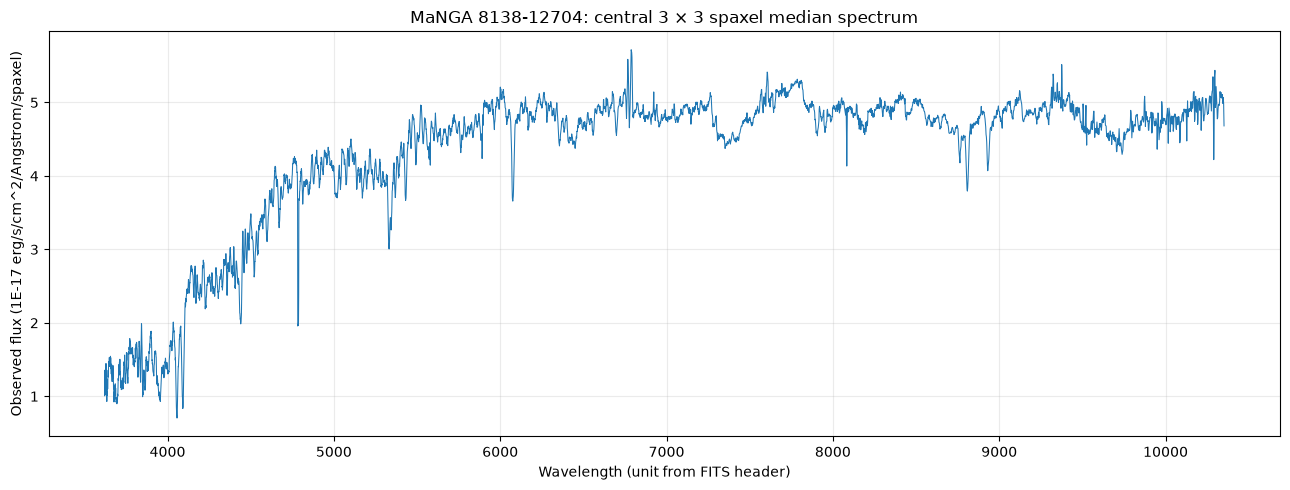

In [11]:
flux_unit = drp_cube["FLUX"].header.get("BUNIT", "unit from FITS header")
wave_unit = drp_cube["WAVE"].header.get("BUNIT", "unit from FITS header")

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(wave, central_spectrum, linewidth=0.75)
ax.set_xlabel(f"Wavelength ({wave_unit})")
ax.set_ylabel(f"Observed flux ({flux_unit})")
ax.set_title("MaNGA 8138-12704: central 3 × 3 spaxel median spectrum")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 11. Compare the DAP binned spectrum with its stellar-continuum model

**Important for HYB10:** The stellar-continuum fit is measured from Voronoi-binned spectra. Therefore, compare the `STELLAR` model to the corresponding binned `FLUX` spectrum in the **DAP LOGCUBE**, not to one individual spaxel from the original DRP LOGCUBE.

The DAP LOGCUBE `BINID` extension has separate planes for the binned spectra and stellar-continuum results. We select a spatial location with valid IDs in both planes and verify the IDs before plotting.

This is a diagnostic comparison. `STELLAR` is the first-stage stellar-continuum model; it is not the same as the full `MODEL` extension from the later emission-line fitting stage.


DAP FLUX shape: (4563, 72, 72)
DAP STELLAR shape: (4563, 72, 72)
DAP BINID shape: (5, 72, 72)
Selected spatial position: y=36, x=36
Binned-spectrum BINID: 184
Stellar-continuum BINID: 184
Finite unmasked DAP FLUX samples: 4556
Finite unmasked STELLAR samples: 2587
DAP FLUX BUNIT: 1E-17 erg/s/cm^2/ang/spaxel
STELLAR BUNIT: 1E-17 erg/s/cm^2/ang/spaxel


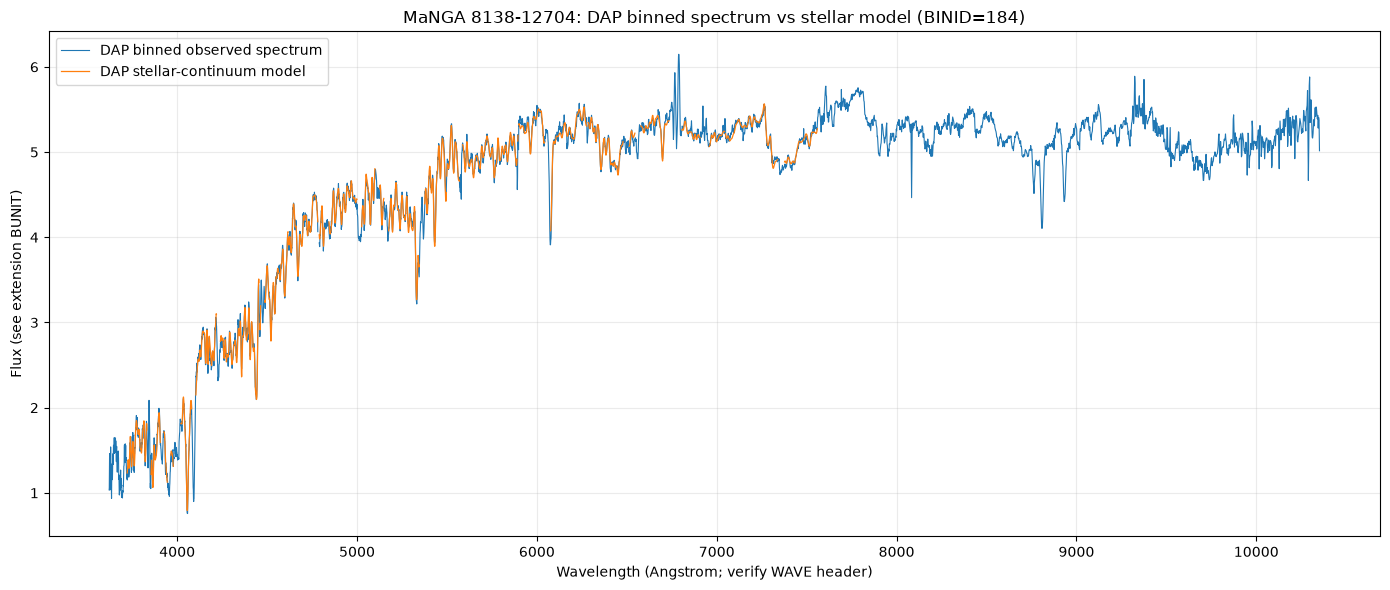

In [12]:
# Compare the DAP binned input spectrum with its first-stage stellar-continuum model.
# For HYB10, use DAP LOGCUBE FLUX and STELLAR at the same stellar bin.

dap_flux = np.asarray(dap_cube["FLUX"].data, dtype=float)
stellar_model = np.asarray(dap_cube["STELLAR"].data, dtype=float)
dap_binid = np.asarray(dap_cube["BINID"].data)

print("DAP FLUX shape:", dap_flux.shape)
print("DAP STELLAR shape:", stellar_model.shape)
print("DAP BINID shape:", dap_binid.shape)

if dap_flux.shape != stellar_model.shape:
    raise ValueError("DAP FLUX and STELLAR cubes do not have matching shapes.")

if dap_binid.ndim != 3 or dap_binid.shape[0] < 2:
    raise ValueError("Expected DAP BINID with at least two planes.")

# DAP LOGCUBE BINID planes:
# 0 = binned spectra; 1 = stellar-continuum fit bins.
spectral_bin_id = dap_binid[0]
stellar_bin_id = dap_binid[1]

# Find positions that have a valid binned spectrum and stellar fit.
valid_positions = (
    (spectral_bin_id >= 0)
    & (stellar_bin_id >= 0)
)

positions = np.argwhere(valid_positions)

if positions.size == 0:
    raise ValueError("No spatial position has both a valid spectrum and stellar-fit bin.")

# Choose the valid position nearest the spatial centre.
ny, nx = spectral_bin_id.shape
cy, cx = ny // 2, nx // 2
distance_squared = (
    (positions[:, 0] - cy) ** 2
    + (positions[:, 1] - cx) ** 2
)
y, x = positions[np.argmin(distance_squared)]

spec_bin = int(spectral_bin_id[y, x])
star_bin = int(stellar_bin_id[y, x])

print(f"Selected spatial position: y={y}, x={x}")
print("Binned-spectrum BINID:", spec_bin)
print("Stellar-continuum BINID:", star_bin)

# For a direct same-bin comparison, require the selected position to map
# to the same bin identifier in both relevant BINID planes.
if spec_bin != star_bin:
    raise ValueError(
        "The selected position has different spectral and stellar BINIDs. "
        "Select a position where the two BINID planes agree before comparing."
    )

# Both arrays are taken from the DAP LOGCUBE at the selected bin location.
observed_binned = dap_flux[:, y, x]
stellar_fit = stellar_model[:, y, x]

# Use the corresponding DAP spectral masks for a conservative display.
dap_data_mask = np.asarray(dap_cube["MASK"].data[:, y, x])
stellar_fit_mask = np.asarray(dap_cube["STELLAR_MASK"].data[:, y, x])

valid_data = np.isfinite(observed_binned) & (dap_data_mask == 0)
valid_stellar = np.isfinite(stellar_fit) & (stellar_fit_mask == 0)

observed_plot = np.where(valid_data, observed_binned, np.nan)
stellar_plot = np.where(valid_stellar, stellar_fit, np.nan)

dap_wave = np.asarray(dap_cube["WAVE"].data, dtype=float)
if dap_wave.shape[0] != observed_binned.shape[0]:
    raise ValueError("DAP WAVE and DAP spectrum lengths do not match.")

print("Finite unmasked DAP FLUX samples:", int(valid_data.sum()))
print("Finite unmasked STELLAR samples:", int(valid_stellar.sum()))
print("DAP FLUX BUNIT:", dap_cube["FLUX"].header.get("BUNIT", "Not specified"))
print("STELLAR BUNIT:", dap_cube["STELLAR"].header.get("BUNIT", "Not specified"))

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(
    dap_wave,
    observed_plot,
    label="DAP binned observed spectrum",
    linewidth=0.8
)
ax.plot(
    dap_wave,
    stellar_plot,
    label="DAP stellar-continuum model",
    linewidth=0.9
)

ax.set_xlabel("Wavelength (Angstrom; verify WAVE header)")
ax.set_ylabel("Flux (see extension BUNIT)")
ax.set_title(
    f"MaNGA 8138-12704: DAP binned spectrum vs stellar model "
    f"(BINID={spec_bin})"
)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 12. Summary and interpretation checklist

Before moving to stellar-kinematics extraction, record:

- [ ] Confirm all three files refer to plate-IFU `8138-12704`.
- [ ] Record the DAPTYPE and pipeline versions from the headers.
- [ ] Record `BUNIT` for `STELLAR_VEL` and `STELLAR_SIGMA`.
- [ ] Confirm wavelength samples are finite and increasing.
- [ ] Read the descriptions/units of the `SPX_SKYCOO` and `SPX_ELLCOO` planes.
- [ ] Inspect the DAP mask definitions and relevant flags.
- [ ] Confirm the central-region spectrum has finite samples.

### Scientific cautions

1. `IVAR` is inverse variance. Where valid and positive, the corresponding 1-sigma uncertainty is `1 / sqrt(IVAR)`.
2. A DAP mask is a bit field. Do not treat every nonzero value as automatically invalid without considering the flag definitions.
3. The `DONOTUSE` check above is only one part of quality control.
4. HYB10 stellar kinematics are measured on binned spectra. Adjacent spaxels can share a bin's kinematic result.
5. A central 3 × 3 median spectrum is exploratory; it is not a substitute for the DAP's bin-level stellar fit.

**Next notebook:** `03_stellar_kinematics_extraction.ipynb`, where we will apply documented quality flags and construct the velocity and velocity-dispersion maps.


## 13. Close FITS files

Run this cell when you have finished exploring the products. If you need to continue inspecting them, leave the handles open until then.


In [13]:
for hdul in (maps, drp_cube, dap_cube):
    hdul.close()

print("All FITS files closed.")


All FITS files closed.
